# Declaratorias asociadas a CT por tipo: Emergencia, Desastre y Contingencia (6 h)

Usa las salidas **ya calculadas** de `scripts/declaratorias_6h.py` (versión de 6 h, `outputs/diagnostics/declaratorias_6h/`); no vuelve a leer MSWEP.

- **P_evento**: máximo de 6 h de la declaratoria en el municipio (ventanas con CT).
- **dif_Pxx** = P_evento − Pxx del mismo píxel (mm (6 h)⁻¹). Negativo: la declaratoria se emitió con menos lluvia que ese percentil.
- **Emergencia**: preventiva, se emite ante la amenaza (puede ser antes de la lluvia). **Desastre**: se emite tras verificar daños. **Contingencia climatológica**: daños al sector agropecuario.

## 1. Lectura

In [9]:
from pathlib import Path

import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.colors import BoundaryNorm, ListedColormap

REPO = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
OUT = REPO / "outputs/diagnostics/declaratorias_6h"
FIG = REPO / "outputs/figures/declaratorias_6h_por_tipo"
FIG.mkdir(parents=True, exist_ok=True)

EXCLUIR_NO_ESPECIFICA = False   # "No se especifican los municipios afectados" (p. ej. TT Rosa 2000)
N_MIN = 3                     # declaratorias mínimas por municipio para mapear el mínimo

ev = pd.read_csv(OUT / "declaratorias_ct_eventos.csv", dtype={"CVEGEO": str}, parse_dates=["t_pico"])
ev = ev[ev["P_evento"].notna()].copy()
ev["no_especifica"] = ev["Observaciones"].str.lower().str.contains("no se especifica", na=False)
print(f"Declaratorias con datos: {len(ev):,} | no especifican municipio: {ev['no_especifica'].sum():,}")
if EXCLUIR_NO_ESPECIFICA:
    ev = ev[~ev["no_especifica"]]

LABS = [c.replace("dif_", "") for c in ev.columns if c.startswith("dif_")]
TIPOS = ["Emergencia", "Desastre", "Contingencia Climatológica"]
COL = dict(zip(TIPOS, ["#eb6834", "#2a78d6", "#1baf7a"]))    # identidad por tipo, orden fijo
print("Percentiles:", LABS)
ev["Tipo Declaratoria"].value_counts()

Declaratorias con datos: 10,437 | no especifican municipio: 1,140
Percentiles: ['P75', 'P90', 'P95', 'P99', 'P99_9']


Tipo Declaratoria
Emergencia                    5794
Desastre                      4388
Contingencia Climatológica     255
Name: count, dtype: int64

## 2. Resumen por tipo

In [10]:
def resumen(g):
    r = {"n": len(g), "municipios": g["CVEGEO"].nunique(),
         "% < 1 mm": 100 * (g["P_evento"] < 1).mean(),
         "P5": g["P_evento"].quantile(0.05), "P10": g["P_evento"].quantile(0.10), "mediana": g["P_evento"].median(),
         "% dentro ROCLOUD": 100 * (g["dentro_rocloud_pico"] == True).mean()}   # noqa: E712
    r.update({f"% < {l}": 100 * (g[f"dif_{l}"] < 0).mean() for l in LABS})
    return pd.Series(r)

tabla = pd.concat({t: resumen(ev[ev["Tipo Declaratoria"].eq(t)]) for t in TIPOS} | {"todas": resumen(ev)}, axis=1).T
tabla.astype(float).round(1)

,n,municipios,% < 1 mm,P5,P10,mediana,% dentro ROCLOUD,% < P75,% < P90,% < P95,% < P99,% < P99_9
Emergencia,5794.0,1625.0,18.0,0.0,0.2,25.7,78.8,37.5,46.7,53.2,71.5,91.9
Desastre,4388.0,1482.0,0.9,11.0,19.8,61.8,89.5,3.8,8.5,15.0,41.0,82.2
Contingencia Climatológica,255.0,219.0,0.0,20.5,29.6,64.7,94.5,1.2,5.5,10.6,25.9,61.2
todas,10437.0,1712.0,10.4,0.1,0.9,45.9,83.7,22.4,29.6,36.1,57.5,87.1


In [11]:
# Distancia al percentil (mm): mediana y P10 por tipo
pd.concat({t: pd.DataFrame({"mediana": [ev.loc[ev["Tipo Declaratoria"].eq(t), f"dif_{l}"].median() for l in LABS],
                            "P10": [ev.loc[ev["Tipo Declaratoria"].eq(t), f"dif_{l}"].quantile(0.1) for l in LABS]},
                           index=LABS) for t in TIPOS}, axis=1).astype(float).round(1)

Emergencia        Desastre       Contingencia Climatológica      
         mediana    P10  mediana   P10                    mediana   P10
P75         14.6   -9.4     50.7  10.7                       54.1  17.9
P90          4.6  -20.1     40.3   2.3                       46.1   7.3
P95         -4.5  -29.7     30.8  -5.7                       38.1  -1.0
P99        -24.4  -57.9      6.4 -28.0                       19.6 -19.0
P99_9      -53.4 -104.6    -28.9 -70.3                       -9.0 -59.6

## 3. Distribuciones

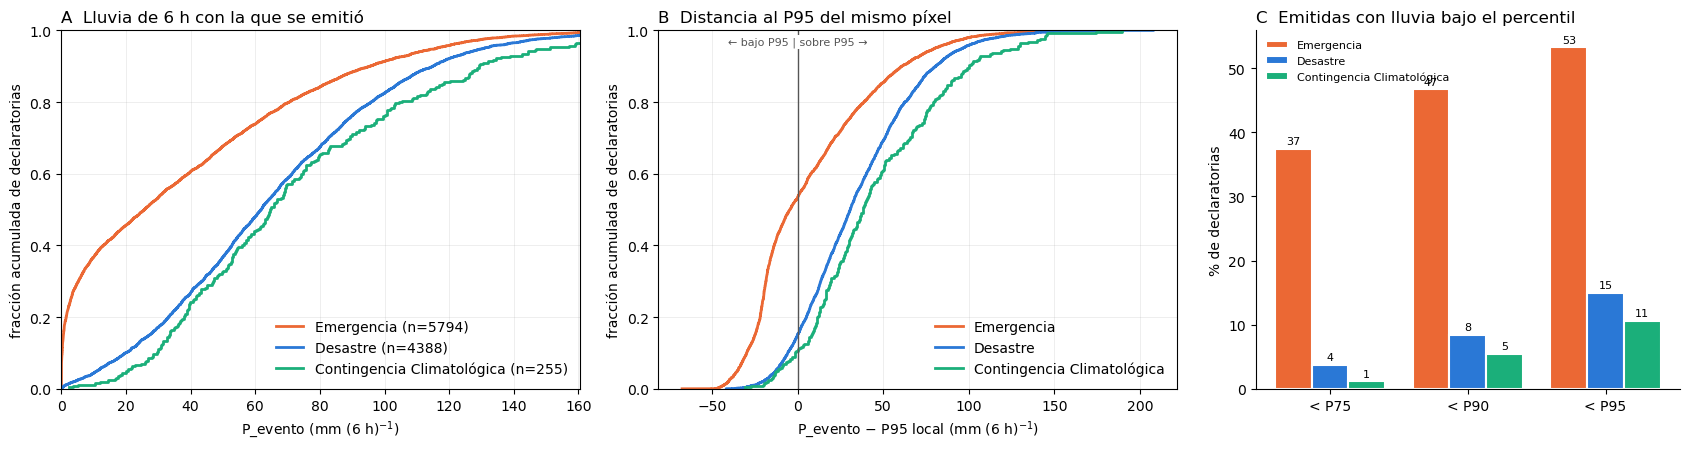

In [12]:
REF = [l for l in ("P75", "P90", "P95") if l in LABS]

def ecdf(ax, x, **kw):
    x = np.sort(np.asarray(x, dtype=float)); x = x[np.isfinite(x)]
    ax.step(x, np.arange(1, x.size + 1) / x.size, where="post", lw=2, **kw)

fig, axs = plt.subplots(1, 3, figsize=(17, 4.6), gridspec_kw={"width_ratios": [1.1, 1.1, 0.9]})

for t in TIPOS:
    g = ev[ev["Tipo Declaratoria"].eq(t)]
    ecdf(axs[0], g["P_evento"], color=COL[t], label=f"{t} (n={len(g)})")
    ecdf(axs[1], g["dif_P95"], color=COL[t], label=t)
axs[0].set_xlim(0, np.nanpercentile(ev["P_evento"], 99))
axs[0].set_xlabel("P_evento (mm (6 h)$^{-1}$)")
axs[0].set_title("A  Lluvia de 6 h con la que se emitió", loc="left")
axs[1].axvline(0, color="#555555", lw=1)
axs[1].annotate("← bajo P95 | sobre P95 →", (0, 0.96), ha="center", fontsize=8, color="#555555",
                bbox=dict(fc="white", ec="none", pad=1))
axs[1].set_xlabel("P_evento − P95 local (mm (6 h)$^{-1}$)")
axs[1].set_title("B  Distancia al P95 del mismo píxel", loc="left")
for ax in axs[:2]:
    ax.set_ylabel("fracción acumulada de declaratorias"); ax.set_ylim(0, 1)
    ax.grid(alpha=0.3, lw=0.5); ax.legend(frameon=False, loc="lower right")

# C: % de declaratorias bajo cada percentil, por tipo
w = 0.8 / len(TIPOS)
x = np.arange(len(REF))
for k, t in enumerate(TIPOS):
    vals = [tabla.loc[t, f"% < {l}"] for l in REF]
    b = axs[2].bar(x + (k - 1) * w, vals, width=w, color=COL[t], edgecolor="white", linewidth=1.5, label=t)
    axs[2].bar_label(b, fmt="%.0f", padding=2, fontsize=8)
axs[2].set_xticks(x, [f"< {l}" for l in REF])
axs[2].set_ylabel("% de declaratorias")
axs[2].spines[["top", "right"]].set_visible(False)
axs[2].legend(frameon=False, fontsize=8)
axs[2].set_title("C  Emitidas con lluvia bajo el percentil", loc="left")

fig.tight_layout()
fig.savefig(FIG / "fig_tipos_distribuciones.png", dpi=300, bbox_inches="tight")

## 4. Misma tormenta y mismo municipio: Emergencia vs Desastre

Pares de declaratorias de ambos tipos en el mismo municipio con el mismo CT en el pico. Si la Emergencia se emitió antes de la lluvia, su P_evento queda por debajo del Desastre.

Pares municipio–CT con ambos tipos: 2,555 | Emergencia < Desastre: 27.0 % | iguales: 70.9 % | mediana Emergencia − Desastre: 0.0 mm


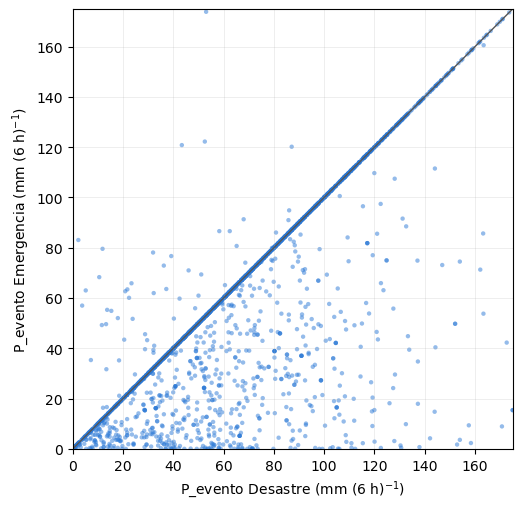

In [13]:
k = ["CVEGEO", "CT_pico"]
em = ev[ev["Tipo Declaratoria"].eq("Emergencia")].groupby(k)["P_evento"].max()
de = ev[ev["Tipo Declaratoria"].eq("Desastre")].groupby(k)["P_evento"].max()
pares = pd.concat({"Emergencia": em, "Desastre": de}, axis=1).dropna()
d = pares["Emergencia"] - pares["Desastre"]
print(f"Pares municipio–CT con ambos tipos: {len(pares):,} | Emergencia < Desastre: {100 * (d < 0).mean():.1f} % "
      f"| iguales: {100 * (d.abs() < 0.01).mean():.1f} % | mediana Emergencia − Desastre: {d.median():.1f} mm")

fig, ax = plt.subplots(figsize=(5.5, 5.2))
ax.scatter(pares["Desastre"], pares["Emergencia"], s=10, color="#2a78d6", alpha=0.5, edgecolor="none")
lim = np.nanpercentile(pares.values, 99.5)
ax.plot([0, lim], [0, lim], color="#555555", lw=1)
ax.set(xlim=(0, lim), ylim=(0, lim), aspect="equal",
       xlabel="P_evento Desastre (mm (6 h)$^{-1}$)", ylabel="P_evento Emergencia (mm (6 h)$^{-1}$)")
ax.grid(alpha=0.3, lw=0.5)
fig.tight_layout()
fig.savefig(FIG / "fig_pares_emergencia_desastre.png", dpi=300, bbox_inches="tight")

## 5. Mínimo por municipio y tipo

In [14]:
def minimo_municipal(g):
    i = g["P_evento"].idxmin()
    r = {"n": len(g), "P_min": g.loc[i, "P_evento"], "P_p10": g["P_evento"].quantile(0.10),
         "P_mediana": g["P_evento"].median(), "CT_min": g.loc[i, "CT_pico"], "t_pico_min": g.loc[i, "t_pico"],
         "dist_min_km": g.loc[i, "dist_pico_km"], "obs_min": g.loc[i, "Observaciones"]}
    for l in LABS:
        r[f"{l}_pixel_min"] = g.loc[i, f"{l}_pixel_max"]
        r[f"dif_min_{l}"] = g.loc[i, f"dif_{l}"]
    return pd.Series(r)

mun_tipo = (ev.groupby(["Tipo Declaratoria", "CVEGEO"])[ev.columns.drop(["Tipo Declaratoria", "CVEGEO"])]
              .apply(minimo_municipal).reset_index())
mun_tipo["suficiente"] = mun_tipo["n"] >= N_MIN
mun_tipo.to_csv(OUT / "por_tipo_municipios.csv", index=False, float_format="%.3f")

pd.DataFrame({t: {"municipios": (m := mun_tipo[mun_tipo["Tipo Declaratoria"].eq(t)]).shape[0],
                  f"con n ≥ {N_MIN}": int(m["suficiente"].sum()),
                  "P_min mediana (n ≥ N_MIN)": m.loc[m["suficiente"], "P_min"].median(),
                  "% P_min < P95 (n ≥ N_MIN)": 100 * (m.loc[m["suficiente"], "dif_min_P95"] < 0).mean()}
              for t in TIPOS}).T.astype(float).round(1)

,municipios,con n ≥ 3,P_min mediana (n ≥ N_MIN),% P_min < P95 (n ≥ N_MIN)
Emergencia,1625.0,961.0,2.2,94.7
Desastre,1482.0,802.0,36.2,39.7
Contingencia Climatológica,219.0,4.0,84.8,0.0


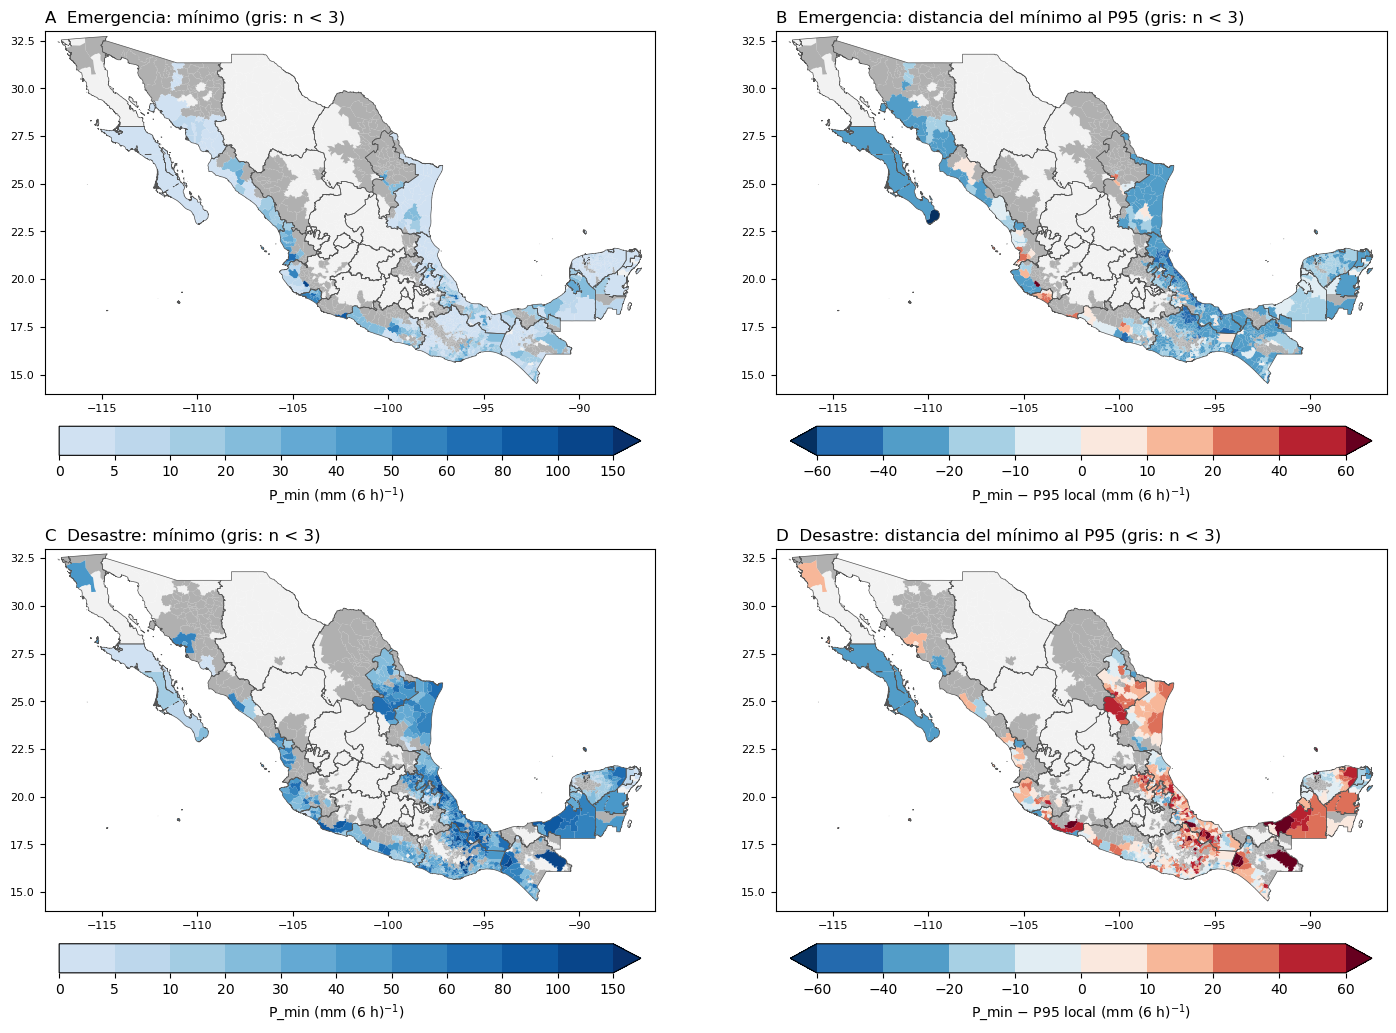

In [15]:
gdf_mun = gpd.read_file(REPO / "data/external/mun23gw/mun23gw.shp", encoding="utf-8")
gdf_mun["CVEGEO"] = gdf_mun["CVEGEO"].astype(str).str.zfill(5)
estados = gdf_mun.dissolve(by="CVE_ENT")

EXT = dict(xlim=(-118, -86), ylim=(14, 33))
B_P = [0, 5, 10, 20, 30, 40, 50, 60, 80, 100, 150]
# Rampa azul sin el tramo casi blanco, para no confundir 0-5 mm con el fondo
CMAP_P = ListedColormap(plt.cm.Blues(np.linspace(0.2, 1.0, len(B_P))))
NORM_P = BoundaryNorm(B_P, CMAP_P.N, extend="max")
B_D = [-60, -40, -20, -10, 0, 10, 20, 40, 60]
CMAP_D, NORM_D = plt.cm.RdBu_r, BoundaryNorm(B_D, plt.cm.RdBu_r.N, extend="both")

fig, axs = plt.subplots(2, 2, figsize=(15, 10.5))
for row, t in enumerate(["Emergencia", "Desastre"]):
    m = gdf_mun[["CVEGEO", "geometry"]].merge(mun_tipo[mun_tipo["Tipo Declaratoria"].eq(t)], on="CVEGEO")
    for col, (var, cmap, norm, lab) in enumerate([("P_min", CMAP_P, NORM_P, "P_min (mm (6 h)$^{-1}$)"),
                                                  ("dif_min_P95", CMAP_D, NORM_D, "P_min − P95 local (mm (6 h)$^{-1}$)")]):
        ax = axs[row, col]
        gdf_mun.plot(ax=ax, color="#f2f2f2", edgecolor="none")
        m[~m["suficiente"]].plot(ax=ax, color="#b0b0b0", edgecolor="none")
        m[m["suficiente"]].plot(ax=ax, column=var, cmap=cmap, norm=norm, edgecolor="none", zorder=2)
        estados.boundary.plot(ax=ax, color="#555555", lw=0.5, zorder=3)
        ax.set(**EXT, aspect="equal"); ax.tick_params(labelsize=8)
        ax.set_title(f"{'ABCD'[2 * row + col]}  {t}: {'mínimo' if col == 0 else 'distancia del mínimo al P95'} "
                     f"(gris: n < {N_MIN})", loc="left")
        fig.colorbar(plt.cm.ScalarMappable(norm=norm, cmap=cmap), ax=ax, orientation="horizontal",
                     shrink=0.8, pad=0.07, ticks=B_P if col == 0 else B_D, label=lab)
fig.tight_layout()
fig.savefig(FIG / "fig_mapas_minimo_por_tipo.png", dpi=300, bbox_inches="tight")

## 6. Municipios con el menor mínimo, por tipo (revisión manual)

In [16]:
TIPO = "Desastre"   # cambiar a "Emergencia" o "Contingencia Climatológica"

cols = ["CVEGEO", "n", "P_min", "P_p10", "P_mediana"] + [f"dif_min_{l}" for l in REF] + \
       ["CT_min", "t_pico_min", "dist_min_km", "obs_min"]
nombres = gdf_mun[["CVEGEO", "NOMGEO", "NOM_ENT"]]
(mun_tipo[mun_tipo["Tipo Declaratoria"].eq(TIPO) & mun_tipo["suficiente"]]
   .sort_values("P_min")[cols].merge(nombres, on="CVEGEO").head(25)
   .round({c: 1 for c in cols if c not in ("CVEGEO", "CT_min", "t_pico_min", "obs_min")}))

,CVEGEO,n,P_min,P_p10,P_mediana,dif_min_P75,dif_min_P90,dif_min_P95,CT_min,t_pico_min,dist_min_km,obs_min,NOMGEO,NOM_ENT
0,21173,4,0.0,30.0,100.6,-11.3,-25.2,-41.7,AL072017,2017-08-09 00:00:00,684.9,Huracán Franklin,Teteles de Ávila Castillo,Puebla
1,21211,4,0.0,4.9,37.4,-9.5,-19.4,-31.3,AL072017,2017-08-09 00:00:00,699.2,Huracán Franklin,Zaragoza,Puebla
2,21208,5,0.0,4.6,47.4,-6.6,-12.8,-18.8,AL072017,2017-08-09 00:00:00,742.5,Huracán Franklin,Zacatlán,Puebla
3,21016,5,0.0,7.8,22.9,-7.8,-13.6,-18.4,AL072017,2017-08-09 00:00:00,735.4,Huracán Franklin,Aquixtla,Puebla
4,21017,5,0.0,35.4,100.1,-11.3,-25.2,-41.7,AL072017,2017-08-09 00:00:00,684.9,Huracán Franklin,Atempan,Puebla
5,06007,13,0.0,1.3,81.9,-10.2,-21.0,-31.1,EP022015,2015-06-07 00:00:00,623.9,Huracan Blanca. Archipielago de Revillagigedo,Manzanillo,Colima
6,21212,4,0.0,30.1,105.1,-8.5,-16.6,-24.1,AL072017,2017-08-09 18:00:00,346.2,Huracán Franklin,Zautla,Puebla
7,03002,12,0.1,38.2,70.4,-6.2,-15.8,-25.7,EP142017,2017-08-31 00:00:00,882.0,Tormenta tropical Lidia,Mulegé,Baja California Sur
8,21200,5,0.4,14.8,63.5,-10.4,-21.6,-33.4,AL072017,2017-08-09 18:00:00,341.3,Huracán Franklin,Xochiapulco,Puebla
9,21167,5,0.6,1.6,17.4,-8.2,-16.7,-23.4,AL072017,2017-08-09 18:00:00,363.0,Huracán Franklin,Tepetzintla,Puebla
